> **Superseded (2026-11-25).** Kept for the record of how the project developed. The current pipeline is `ev_siting_final.ipynb` (EV-registration demand weight, audit fixes, all models and scenarios in one notebook). Numbers here use the earlier population-based weight.

# EV Charging Optimizer (Delhi): Evaluation, sensitivity and extensions

Compares the three siting models on a common scorecard and tests extensions. All shared code is in
`siting_lib.py`; baseline layouts come from the grid rule (reproduced here), `ev_kmeans_model_v2.ipynb` and
`ev_mclp_model.ipynb`.

1. Baseline layouts (Scenario A, 104 stations)
2. Evaluation scorecard: one circular and several independent yardsticks, plus a regret table
3. Consensus sites: where all three methods agree
4. Existing chargers (Scenario B): what the current network covers and where new stations should go
5. Extensions: real candidate sites, road distance, capacity cap, p-median and gradual coverage
6. Sensitivity: grid size 3 / 2 / 1 km and the number of stations for K-means and MCLP
7. Exports (GeoPackage for GIS, CSV tables)

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

import siting_lib as sl

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
OUT = Path("outputs/evaluation_v1"); OUT.mkdir(parents=True, exist_ok=True)
B = sl.load_base()
X, w = B["X"], B["w"]
road = sl.RoadNet()
P = 104
LAYOUTS = {}          # name -> (n x 2) station coordinates, all exported at the end
print(f"demand cells {len(X)} | real candidate sites (OSM parking + fuel) {len(B['real_sites'])} | "
      f"existing chargers {len(B['existing_all'])} (confirmed 4W {len(B['existing_4w'])})")

demand cells 1570 | real candidate sites (OSM parking + fuel) 811 | existing chargers 1323 (confirmed 4W 98)


## 1. Baseline layouts (Scenario A: 104 new stations, existing chargers ignored)

In [2]:
grid3, gcells3 = sl.grid_model(B, 3)
km = sl.pts(pd.read_csv("outputs/kmeans_v2/kmeans_A_k104_stations.csv"))
mc = sl.pts(pd.read_csv("outputs/mclp_v1/mclp_A_p104_R2100_stations.csv"))
base = {"Grid (3 km, 1%)": sl.xy(grid3), "K-means (k=104)": sl.xy(km), "MCLP (p=104, R=2.1 km)": sl.xy(mc)}
LAYOUTS.update({"A_grid_3km": base["Grid (3 km, 1%)"], "A_kmeans_104": base["K-means (k=104)"], "A_mclp_104": base["MCLP (p=104, R=2.1 km)"]})
print({k: len(v) for k, v in base.items()})

{'Grid (3 km, 1%)': 104, 'K-means (k=104)': 104, 'MCLP (p=104, R=2.1 km)': 104}


## 2. Evaluation scorecard

**Why no single "accurate" evaluation exists.** There is no observed charging demand in Delhi to test against.
K-means and MCLP were built from the demand weights, so scoring them on those weights is circular; the grid
was built to cover area evenly, so scoring on area favours it. The best available approach is to score every
layout on **many yardsticks**, most of which **no model used**, and look for the layout that is never far from
the best (smallest worst-case regret).

| Yardstick | Used to build a model? | Reads as |
|---|---|---|
| model demand within 2.1 km | yes (K-means, MCLP): circular | how well the layout fits our own estimate |
| EV registrations within 2.1 km | no (VAHAN data, RTO-zone rates) | where EV owners actually are registered |
| population within 2.1 km | partly (R ≈ population) | residents served |
| destinations within 2.1 km | partly (D) | daytime activity served |
| area within 2.1 km | no (grid's logic) | Delhi's "charger within 3 km of anywhere" goal |
| mean / 95th pct / max distance | no | typical and worst access |
| worst SC quintile coverage, Gini of distance | no | equity |
| existing chargers within 1 km | no | agreement with where operators already invested |
| sites within 500 m of parking/fuel; within 200 m of a road | no | buildability |
| road distance (mean; demand and population within 3 km by road) | no (all models use straight lines) | real access, Delhi's "3 km travel" goal |

In [3]:
rows = [sl.scorecard_row(B, S, n, road=road) for n, S in base.items()]
rows += [sl.scorecard_row(B, sl.xy(B["existing_4w"]), "Existing confirmed 4W (98)", road=road),
         sl.scorecard_row(B, sl.xy(B["existing_all"]), "Existing all chargers (1,323)", road=road)]
card = pd.DataFrame(rows).set_index("layout")
card.T.round(1)

layout,"Grid (3 km, 1%)",K-means (k=104),"MCLP (p=104, R=2.1 km)",Existing confirmed 4W (98),"Existing all chargers (1,323)"
stations,104.0,104.0,104.0,98.0,1323.0
model_demand_cov_pct,83.8,95.3,94.4,64.8,95.4
ev_registrations_cov_pct,85.7,97.4,96.5,70.4,97.6
population_cov_pct,83.7,98.1,97.5,68.9,97.9
destinations_cov_pct,83.9,91.0,89.7,58.8,91.5
area_cov_pct,65.7,76.3,73.3,39.4,78.0
mean_dist_m,1456.8,1145.1,1255.6,2118.5,645.7
p95_dist_m,3018.7,2075.4,2103.6,6041.3,1972.3
max_dist_any_cell_m,9658.4,5376.0,8466.5,14033.2,10300.5
worst_sc_quintile_pop_cov_pct,76.0,92.2,88.1,44.7,93.4


**Regret table.** For each yardstick, how far each of the three methods falls short of the best of the three
(0 = best, 0.10 = 10% worse). The last columns give each method's worst and average shortfall.

In [4]:
reg = sl.regret_table(card.loc[list(base)])
reg_summary = pd.DataFrame({"worst_regret": reg.max(1), "mean_regret": reg.mean(1),
                            "yardsticks_won": (reg == 0).sum(1), "worst_on": reg.idxmax(1)})
display(reg.T.round(3))
reg_summary.round(3)

layout,"Grid (3 km, 1%)",K-means (k=104),"MCLP (p=104, R=2.1 km)"
model_demand_cov_pct,0.121,0.000,0.009
ev_registrations_cov_pct,0.120,0.000,0.009
population_cov_pct,0.148,0.000,0.006
destinations_cov_pct,0.078,0.000,0.015
area_cov_pct,0.139,0.000,0.039
mean_dist_m,0.272,0.000,0.096
p95_dist_m,0.454,0.000,0.014
max_dist_any_cell_m,0.797,0.000,0.575
worst_sc_quintile_pop_cov_pct,0.176,0.000,0.045
gini_access_dist_pop,0.201,0.070,0.000


,worst_regret,mean_regret,yardsticks_won,worst_on
layout,,,,
"Grid (3 km, 1%)",0.797,0.199,0,max_dist_any_cell_m
K-means (k=104),0.070,0.005,15,gini_access_dist_pop
"MCLP (p=104, R=2.1 km)",0.575,0.075,3,max_dist_any_cell_m


## 3. Consensus sites: where all three methods agree

Grid and MCLP both pick from the same 3 km candidate points, so they "agree" when they pick the same point.
A consensus site is a point chosen by **both grid and MCLP** that also has a **K-means station within 1 km**
(1.5 km reported too). These are no-regret locations: three methods built on different logic (policy rule,
demand-weighted distance, coverage optimisation) all want a station there. Caveat: the methods share inputs
(land use, demand layer) and grid/MCLP share the candidate lattice, so agreement is strong evidence, not proof.

In [5]:
G, K, M = base["Grid (3 km, 1%)"], base["K-means (k=104)"], base["MCLP (p=104, R=2.1 km)"]
gm = cKDTree(M).query(G)[0] < 1                                  # grid sites also chosen by MCLP
dk, ik = cKDTree(K).query(G)
cons = grid3[gm].copy()
cons["kmeans_dist_m"] = dk[gm]
cons["kmeans_persistence"] = km["persistence"].to_numpy()[ik[gm]]
cons["mclp_persistence"] = mc["persistence"].to_numpy()[cKDTree(M).query(sl.xy(cons))[1]]
cons["all_three_1km"] = cons["kmeans_dist_m"] <= 1000
cons["all_three_1_5km"] = cons["kmeans_dist_m"] <= 1500

cons["ward_no"] = B["demand"]["ward_no"].to_numpy()[cKDTree(X).query(sl.xy(cons))[1]]
wn = pd.read_csv("ward_master_v2.csv").set_index("ward_no")["ward_name"]
cons["ward_name"] = cons["ward_no"].map(wn)
cons["robust_all"] = cons["all_three_1km"] & (cons["kmeans_persistence"] >= 0.5) & (cons["mclp_persistence"] >= 0.8)
print(f"Grid & MCLP same site: {gm.sum()} | + K-means within 1 km: {cons['all_three_1km'].sum()} | "
      f"within 1.5 km: {cons['all_three_1_5km'].sum()} | consensus and stable in the Monte Carlo: {cons['robust_all'].sum()}")
pair = pd.DataFrame({a: {b: sl.agreement(base[a], base[b]) for b in base} for a in base}).T
print("Pairwise agreement (% of row method's stations with a column-method station within 1 km):")
display(pair.round(0))
cons.loc[cons["all_three_1km"], ["ward_no", "ward_name", "share_ci", "kmeans_dist_m", "kmeans_persistence", "mclp_persistence"]] \
    .sort_values("kmeans_dist_m").round(2)

Grid & MCLP same site: 77 | + K-means within 1 km: 26 | within 1.5 km: 55 | consensus and stable in the Monte Carlo: 13
Pairwise agreement (% of row method's stations with a column-method station within 1 km):


,"Grid (3 km, 1%)",K-means (k=104),"MCLP (p=104, R=2.1 km)"
"Grid (3 km, 1%)",100.0,26.0,74.0
K-means (k=104),26.0,100.0,37.0
"MCLP (p=104, R=2.1 km)",74.0,37.0,100.0


,ward_no,ward_name,share_ci,kmeans_dist_m,kmeans_persistence,mclp_persistence
74,147,Kotla Mubarakpur,0.03,298.05,0.66,1.00
84,201,Lalita Park,0.14,341.16,0.72,1.00
17,30,Bawana,0.51,438.84,0.46,1.00
93,224,Welcome Colony,0.02,473.73,0.62,1.00
43,139,Naraina,0.35,537.58,0.84,0.98
42,133,Mahipalpur,0.01,540.97,0.64,0.84
91,200,Pandav Nagar,0.04,595.84,0.76,1.00
16,40,Nithari,0.05,616.45,0.32,1.00
26,2,Bankner,0.10,618.70,0.46,1.00
54,154,Lado Sarai,0.08,639.82,0.20,0.98


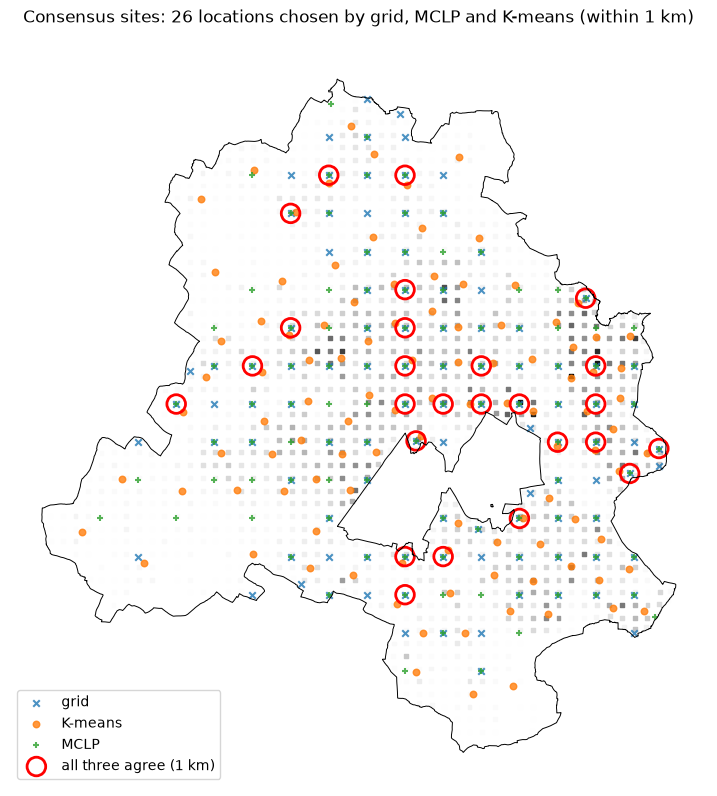

In [6]:
fig, ax = plt.subplots(figsize=(9, 10))
B["study"].boundary.plot(ax=ax, color="k", lw=0.7)
ax.scatter(X[:, 0], X[:, 1], c=w, s=8, cmap="Greys", marker="s")
for S, c, lab, mk in [(G, "tab:blue", "grid", "x"), (K, "tab:orange", "K-means", "o"), (M, "tab:green", "MCLP", "+")]:
    ax.scatter(S[:, 0], S[:, 1], s=22, c=c, marker=mk, label=lab, alpha=0.8)
cc = sl.xy(cons[cons["all_three_1km"]])
ax.scatter(cc[:, 0], cc[:, 1], s=180, facecolors="none", edgecolors="red", lw=2, label="all three agree (1 km)")
ax.legend(loc="lower left"); ax.set_axis_off(); ax.set_aspect("equal")
ax.set_title(f"Consensus sites: {len(cc)} locations chosen by grid, MCLP and K-means (within 1 km)")
plt.savefig(OUT / "consensus_map.png", dpi=130, bbox_inches="tight"); plt.show()

## 4. Existing chargers (Scenario B)

**What adding existing chargers tells us.**
1. *How good is today's network?* The 98 confirmed 4W sites are scored like any layout (section 2).
2. *Where are the gaps?* Demand not within 2.1 km of an existing 4W charger.
3. *Where should the next stations go?* Each method places 104 **new** stations around the existing ones:
   grid drops cells that already have a 4W charger; MCLP keeps the 98 sites open for free; K-means keeps them
   as fixed centres and moves only the new ones.
4. *How many new stations are actually needed* to reach a coverage target, given what exists.

In [7]:
E = sl.xy(B["existing_4w"])
d_ex = cKDTree(E).query(X)[0]
print(f"Existing 4W network alone: {100 * w[d_ex <= 2100].sum() / w.sum():.1f}% of demand within 2.1 km; "
      f"gap = {100 * w[d_ex > 2100].sum() / w.sum():.1f}% of demand in {int((d_ex > 2100).sum())} cells")

# grid B: drop cells containing a confirmed 4W site
has4w = gpd.sjoin(gcells3[gcells3["station"]][["cell_id", "geometry"]], B["existing_4w"][["geometry"]], predicate="contains")["cell_id"].unique()
gB = grid3[~grid3["cell_id"].isin(has4w)]
# MCLP B: candidates = 3 km points + the 98 existing sites (forced open)
S_B = np.vstack([sl.xy(B["cand3"]), E]); fixed = np.arange(len(B["cand3"]), len(S_B))
oB, _ = sl.mclp(w, sl.within_pairs(X, S_B, 2100), P, sl.within_pairs(X, S_B, 1000), fixed=fixed)
mB_new = S_B[np.setdiff1d(oB, fixed)]
# K-means B: existing as fixed centres
kB_new, _ = sl.kmeans_fixed(X, w, E, P)
scenB = {"Grid B (new)": sl.xy(gB), "K-means B (new)": kB_new, "MCLP B (new)": mB_new}
LAYOUTS.update({"B_grid_new": sl.xy(gB), "B_kmeans_new": kB_new, "B_mclp_new": mB_new})
rowsB = [sl.scorecard_row(B, np.vstack([E, S]), f"{n.split(' (')[0]}: existing 98 + {len(S)} new", road=road) for n, S in scenB.items()]
rowsB.append(sl.scorecard_row(B, E, "Existing 98 only", road=road))
cardB = pd.DataFrame(rowsB).set_index("layout")
print({n: len(S) for n, S in scenB.items()})
cardB[["stations", "model_demand_cov_pct", "ev_registrations_cov_pct", "area_cov_pct", "mean_dist_m",
       "worst_sc_quintile_pop_cov_pct", "road_3000m_model_demand_cov_pct"]].round(1)

Existing 4W network alone: 64.8% of demand within 2.1 km; gap = 35.2% of demand in 981 cells


{'Grid B (new)': 59, 'K-means B (new)': 104, 'MCLP B (new)': 104}


,stations,model_demand_cov_pct,ev_registrations_cov_pct,area_cov_pct,mean_dist_m,worst_sc_quintile_pop_cov_pct,road_3000m_model_demand_cov_pct
layout,,,,,,,
Grid B: existing 98 + 59 new,157,87.0,89.1,68.5,1320.3,72.8,77.3
K-means B: existing 98 + 104 new,202,98.3,99.1,88.1,903.5,96.1,90.8
MCLP B: existing 98 + 104 new,202,99.5,99.7,95.3,1063.8,99.5,88.0
Existing 98 only,98,64.8,70.4,39.4,2118.5,44.7,57.5


**How many new stations are needed?** MCLP with the existing 98 kept open, for an increasing number of new
stations (3 km candidates, R = 2.1 km).

In [8]:
curve = []
A_B = sl.within_pairs(X, S_B, 2100)
for p_new in [0, 10, 20, 30, 40, 50, 60, 80, 104, 130, 160]:
    o, cv = sl.mclp(w, A_B, p_new, fixed=fixed)
    curve.append(dict(new_stations=p_new, demand_cov_pct=100 * cv / w.sum()))
curve = pd.DataFrame(curve)
need = {t: int(curve.loc[curve["demand_cov_pct"] >= t, "new_stations"].min()) if (curve["demand_cov_pct"] >= t).any() else None for t in [90, 95, 99]}
print("New stations needed (on top of the existing 98) for:", {f"{t}%": v for t, v in need.items()})
curve.round(1).T

New stations needed (on top of the existing 98) for: {'90%': 40, '95%': 60, '99%': 104}


,0,1,2,3,4,5,6,7,8,9,10
new_stations,0.0,10.0,20.0,30.0,40.0,50.0,60.0,80.0,104.0,130.0,160.0
demand_cov_pct,64.8,77.1,83.9,88.2,91.3,93.6,95.6,98.0,99.5,100.0,100.0


## 5. Extensions: do they change anything meaningful?

Each variant is compared with its baseline on the scorecard and on **how many of its sites moved**
(share of variant stations with no baseline station within 1 km). A change matters if coverage/distance moves
by more than about a point / 50 m, or if many sites move.

In [9]:
def moved(Snew, Sbase, r=1000):
    return 100 - sl.agreement(Snew, Sbase, r)

ext, ext_layouts = [], {}
def add(name, S, Sbase, note):
    ext_layouts[name] = S
    r = sl.scorecard_row(B, S, name, road=road); r["sites_moved_vs_baseline_pct"] = moved(S, Sbase); r["note"] = note
    ext.append(r)

# baselines
add("MCLP baseline (3 km candidates)", M, M, "baseline")
add("K-means baseline", K, K, "baseline")

# 5.2 real candidate sites: OSM parking + fuel stations (811)
RS = sl.xy(B["real_sites"])
o, cv = sl.mclp(w, sl.within_pairs(X, RS, 2100), P, sl.within_pairs(X, RS, 1000))
add("MCLP on real sites (OSM parking/fuel)", RS[o], M, "candidates = 811 OSM parking + fuel sites")
o = sl.pmedian(w, X, RS, P)
add("K-medoids / p-median on real sites", RS[o], K, "K-means analogue restricted to real sites")

# 5.3 road distance (directed network, oneway respected)
Dr3 = road.dist_to(X, sl.xy(B["cand3"]))
o, cv = sl.mclp(w, sl.csr_matrix((Dr3 <= 3000).astype(float)), P, sl.csr_matrix((Dr3 <= 1500).astype(float)))
add("MCLP road (3 km by road, 3 km candidates)", sl.xy(B["cand3"])[o], M, "coverage = within 3 km by road (Delhi's '3 km travel')")
C1 = X                                                      # 1 km cell centres as candidates for the p-median runs
t0 = time.time(); Dr1 = road.dist_to(X, C1); print(f"road matrix 1570 x 1570 in {time.time() - t0:.0f}s")
o = sl.pmedian(w, X, C1, P)
pm_eu = C1[o]
add("p-median Euclidean (1 km cell candidates)", pm_eu, K, "linear-distance K-means analogue")
o = sl.pmedian(w, X, C1, P, dist=np.where(np.isfinite(Dr1), Dr1, 1e7))
add("p-median road distance (1 km cell candidates)", C1[o], K, "K-means analogue on road distance")

# 5.5 coverage models
o, cv = sl.mclp_gradual(w, X, sl.xy(B["cand3"]), P)
add("MCLP gradual coverage (1 km full -> 3 km zero)", sl.xy(B["cand3"])[o], M, "no hard 2.1 km cut-off")

extA = pd.DataFrame(ext).set_index("layout")
extA[["stations", "sites_moved_vs_baseline_pct", "model_demand_cov_pct", "ev_registrations_cov_pct", "area_cov_pct",
      "mean_dist_m", "road_mean_dist_m", "road_3000m_model_demand_cov_pct", "sites_within_500m_of_parking_or_fuel_pct",
      "worst_sc_quintile_pop_cov_pct", "note"]].round(1)

road matrix 1570 x 1570 in 14s


,stations,sites_moved_vs_baseline_pct,model_demand_cov_pct,ev_registrations_cov_pct,area_cov_pct,mean_dist_m,road_mean_dist_m,road_3000m_model_demand_cov_pct,sites_within_500m_of_parking_or_fuel_pct,worst_sc_quintile_pop_cov_pct,note
layout,,,,,,,,,,,
MCLP baseline (3 km candidates),104,0.0,94.4,96.5,73.3,1255.6,2216.8,82.8,23.1,88.1,baseline
K-means baseline,104,0.0,95.3,97.4,76.3,1145.1,2040.4,84.8,28.8,92.2,baseline
MCLP on real sites (OSM parking/fuel),104,69.2,88.8,91.2,65.4,1466.3,2465.5,75.8,100.0,78.4,candidates = 811 OSM parking + fuel sites
K-medoids / p-median on real sites,104,61.5,86.7,89.8,60.0,1333.9,2296.1,78.4,100.0,76.0,K-means analogue restricted to real sites
"MCLP road (3 km by road, 3 km candidates)",104,16.3,92.0,95.3,70.7,1290.8,2166.9,85.8,25.0,84.2,coverage = within 3 km by road (Delhi's '3 km ...
p-median Euclidean (1 km cell candidates),104,35.6,92.5,95.8,70.0,1098.0,1901.2,84.4,32.7,89.2,linear-distance K-means analogue
p-median road distance (1 km cell candidates),104,43.3,90.4,94.6,66.9,1154.5,1765.3,88.2,33.7,87.7,K-means analogue on road distance
MCLP gradual coverage (1 km full -> 3 km zero),104,10.6,93.6,95.8,70.8,1242.7,2206.5,83.0,26.9,85.1,no hard 2.1 km cut-off


### 5.4 Capacity cap

**The problem.** Without a cap, one station can be assigned an arbitrarily large share of demand. Below, each
baseline station's *load* = demand of the cells for which it is the nearest station.

**How to set the cap.** Ideally from station throughput:
`cap (weight units) = station sessions per day / total public sessions per day x 1000`, where station sessions =
chargers per station x sessions per charger per day, and total sessions = EVs x share charging in public x
sessions per EV per day. No Delhi throughput data exist, so the cap is set **relative to the average load**:
`cap = alpha x (total weight / number of stations)`, with alpha = 1.5 (a station may serve up to 1.5x an average
station, i.e. stations are built in a few standard sizes), and alpha = 1.25 / 2 as sensitivity.

In [10]:
def loads(S):
    return np.bincount(cKDTree(S).query(X)[1], weights=w, minlength=len(S))

avg = w.sum() / P
ld = pd.DataFrame({n: pd.Series(loads(S) / avg).describe(percentiles=[0.5, 0.9]) for n, S in base.items()}).T
print(f"Average load per station = {avg:.2f} weight units ({avg / 10:.2f}% of Delhi's demand). Load / average:")
display(ld[["mean", "50%", "90%", "max"]].round(2))

cap_rows, cap_layouts = [], {}
for alpha in [1.25, 1.5, 2.0]:
    cap = alpha * avg
    Ck, lk = sl.kmeans_capacitated(X, w, P, cap)
    o, cv, lm = sl.mclp_capacitated(w, X, sl.xy(B["cand3"]), P, 2100, cap)
    Sm = sl.xy(B["cand3"])[o]
    cap_layouts[alpha] = (Ck, Sm)
    for nm, S, Sb in [(f"K-means capacitated (alpha={alpha})", Ck, K), (f"MCLP capacitated (alpha={alpha})", Sm, M)]:
        r = sl.scorecard_row(B, S, nm, road=road)
        r["sites_moved_vs_baseline_pct"] = moved(S, Sb)
        r["max_load_over_avg_nearest"] = loads(S).max() / avg
        if nm.startswith("MCLP"):
            r["served_within_cap_pct"] = 100 * cv / w.sum()
        cap_rows.append(r)
capdf = pd.DataFrame(cap_rows).set_index("layout")
LAYOUTS.update({"A_kmeans_cap1.5": cap_layouts[1.5][0], "A_mclp_cap1.5": cap_layouts[1.5][1]})
capdf[["sites_moved_vs_baseline_pct", "max_load_over_avg_nearest", "served_within_cap_pct", "model_demand_cov_pct",
       "area_cov_pct", "mean_dist_m", "worst_sc_quintile_pop_cov_pct"]].round(2)

Average load per station = 9.62 weight units (0.96% of Delhi's demand). Load / average:


,mean,50%,90%,max
"Grid (3 km, 1%)",1.0,0.83,1.97,3.39
K-means (k=104),1.0,0.96,1.57,2.12
"MCLP (p=104, R=2.1 km)",1.0,0.87,1.65,2.53


,sites_moved_vs_baseline_pct,max_load_over_avg_nearest,served_within_cap_pct,model_demand_cov_pct,area_cov_pct,mean_dist_m,worst_sc_quintile_pop_cov_pct
layout,,,,,,,
K-means capacitated (alpha=1.25),11.54,1.69,NaN,94.34,74.23,1151.12,91.39
MCLP capacitated (alpha=1.25),4.81,2.27,92.72,93.69,70.30,1278.38,85.02
K-means capacitated (alpha=1.5),0.00,1.81,NaN,95.30,76.22,1146.87,92.24
MCLP capacitated (alpha=1.5),0.00,2.53,94.31,94.39,73.26,1255.55,88.11
K-means capacitated (alpha=2.0),0.00,1.99,NaN,95.38,76.33,1144.92,92.24
MCLP capacitated (alpha=2.0),0.00,2.53,94.39,94.39,73.26,1255.55,88.11


## 6. Sensitivity

### 6a. Grid size: 3 km vs 2 km vs 1 km (same 1% rule)

In [11]:
grids = {s: sl.grid_model(B, s)[0] for s in [3, 2, 1]}
for s, g in grids.items():
    LAYOUTS[f"A_grid_{s}km"] = sl.xy(g)
gcard = pd.DataFrame([sl.scorecard_row(B, sl.xy(g), f"Grid {s} km ({len(g)} stations)", road=road) for s, g in grids.items()]).set_index("layout")
gcard[["stations", "model_demand_cov_pct", "ev_registrations_cov_pct", "population_cov_pct", "area_cov_pct", "mean_dist_m",
       "max_dist_any_cell_m", "road_3000m_model_demand_cov_pct", "worst_sc_quintile_pop_cov_pct"]].round(1)

,stations,model_demand_cov_pct,ev_registrations_cov_pct,population_cov_pct,area_cov_pct,mean_dist_m,max_dist_any_cell_m,road_3000m_model_demand_cov_pct,worst_sc_quintile_pop_cov_pct
layout,,,,,,,,,
Grid 3 km (104 stations),104,83.8,85.7,83.7,65.7,1456.8,9658.4,74.6,76.0
Grid 2 km (157 stations),157,86.5,87.6,86.4,68.3,1252.4,9093.1,81.3,76.9
Grid 1 km (404 stations),404,92.4,93.4,93.6,73.9,914.8,8866.8,89.6,87.7


### 6b. Number of stations for K-means and MCLP

Budgets: **104 / 157 / 404** (the 3 / 2 / 1 km grid counts, for a like-for-like comparison with each grid),
**178** (fewest stations putting every cell within 2.1 km straight-line, about 3 km by road: Delhi's policy goal, when sites are limited to the 3 km grid points; with free placement on 1 km cell centres the minimum is about **130**: set-cover solve gave 133 with a proven lower bound of 126). Read as **3 km by road** (directed network, every cell), the minimum is **224** stations (proven optimal; median road/straight detour 1.57), so 2.1 km straight-line matches 3 km by road only on average
and **206** (one per 3 km cell, the Ministry of Power guideline). MCLP needs more candidates than the 206 grid
points for the larger budgets, so this section uses the **1,570 1 km cell centres** as MCLP candidates
(R = 2.1 km, tie-break within 1 km).

In [12]:
A21, A10 = sl.within_pairs(X, C1, 2100), sl.within_pairs(X, C1, 1000)
bud_rows, bud = [], {}
for k in [104, 157, 178, 206, 404]:
    Ck, _ = sl.kmeans(X, w, k, n_init=10)
    t0 = time.time(); o, cv = sl.mclp(w, A21, k, A10, time_limit=180); tm = time.time() - t0
    bud[k] = {"K-means": Ck, "MCLP": C1[o]}
    LAYOUTS[f"A_kmeans_{k}"] = Ck; LAYOUTS[f"A_mclp1km_{k}"] = C1[o]
    for nm, S in bud[k].items():
        r = sl.scorecard_row(B, S, f"{nm} ({k})"); r["budget"] = k; r["method"] = nm
        gm_ = {104: 3, 157: 2, 404: 1}.get(k)
        if gm_:
            r[f"agree_with_grid_{gm_}km_1km_pct"] = sl.agreement(S, sl.xy(grids[gm_]))
        bud_rows.append(r)
    print(f"budget {k}: MCLP solved in {tm:.0f}s")
for s, g in grids.items():
    r = sl.scorecard_row(B, sl.xy(g), f"Grid {s} km ({len(g)})"); r["budget"] = len(g); r["method"] = "Grid"
    bud_rows.append(r)
budf = pd.DataFrame(bud_rows).set_index("layout").sort_values(["budget", "method"])
budf[["method", "budget", "model_demand_cov_pct", "ev_registrations_cov_pct", "area_cov_pct", "mean_dist_m", "max_dist_any_cell_m",
      "worst_sc_quintile_pop_cov_pct"] + [c for c in budf.columns if c.startswith("agree")]].round(1)

budget 104: MCLP solved in 360s


budget 157: MCLP solved in 2s


budget 178: MCLP solved in 1s


budget 206: MCLP solved in 0s


budget 404: MCLP solved in 0s


,method,budget,model_demand_cov_pct,ev_registrations_cov_pct,area_cov_pct,mean_dist_m,max_dist_any_cell_m,worst_sc_quintile_pop_cov_pct,agree_with_grid_3km_1km_pct,agree_with_grid_2km_1km_pct,agree_with_grid_1km_1km_pct
layout,,,,,,,,,,,
Grid 3 km (104),Grid,104,83.8,85.7,65.7,1456.8,9658.4,76.0,NaN,NaN,NaN
K-means (104),K-means,104,95.3,97.4,76.3,1145.1,5376.0,92.2,26.0,NaN,NaN
MCLP (104),MCLP,104,98.8,99.5,89.4,1329.8,5778.1,96.3,29.8,NaN,NaN
Grid 2 km (157),Grid,157,86.5,87.6,68.3,1252.4,9093.1,76.9,NaN,NaN,NaN
K-means (157),K-means,157,98.5,99.4,88.4,929.8,4492.6,97.4,NaN,47.8,NaN
MCLP (157),MCLP,157,100.0,100.0,100.0,1226.1,2099.1,100.0,NaN,39.5,NaN
K-means (178),K-means,178,99.0,99.6,91.8,872.3,4240.8,98.6,NaN,NaN,NaN
MCLP (178),MCLP,178,100.0,100.0,100.0,1150.1,2094.2,100.0,NaN,NaN,NaN
K-means (206),K-means,206,99.4,99.8,94.0,802.6,4146.4,98.4,NaN,NaN,NaN


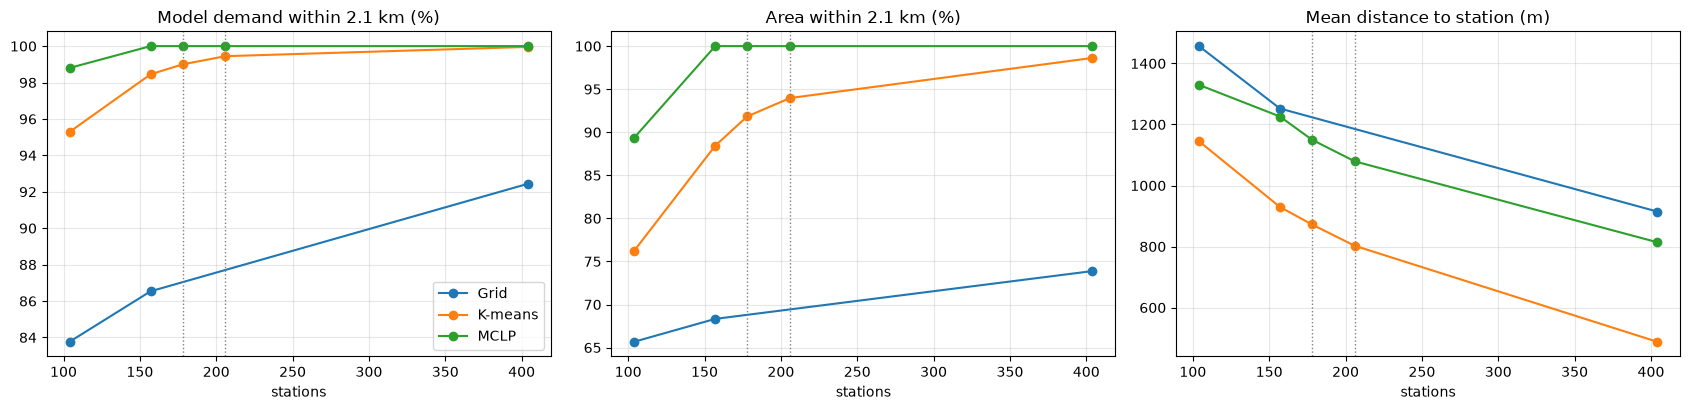

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for m_, c in [("Grid", "tab:blue"), ("K-means", "tab:orange"), ("MCLP", "tab:green")]:
    d = budf[budf["method"] == m_].sort_values("budget")
    for ax, col, ttl in zip(axes, ["model_demand_cov_pct", "area_cov_pct", "mean_dist_m"],
                            ["Model demand within 2.1 km (%)", "Area within 2.1 km (%)", "Mean distance to station (m)"]):
        ax.plot(d["budget"], d[col], marker="o", color=c, label=m_); ax.set_title(ttl); ax.set_xlabel("stations"); ax.grid(alpha=.3)
for ax in axes:
    for b in [178, 206]:
        ax.axvline(b, color="grey", ls=":", lw=1)
axes[0].legend(); plt.tight_layout(); plt.savefig(OUT / "budget_curves.png", dpi=130); plt.show()

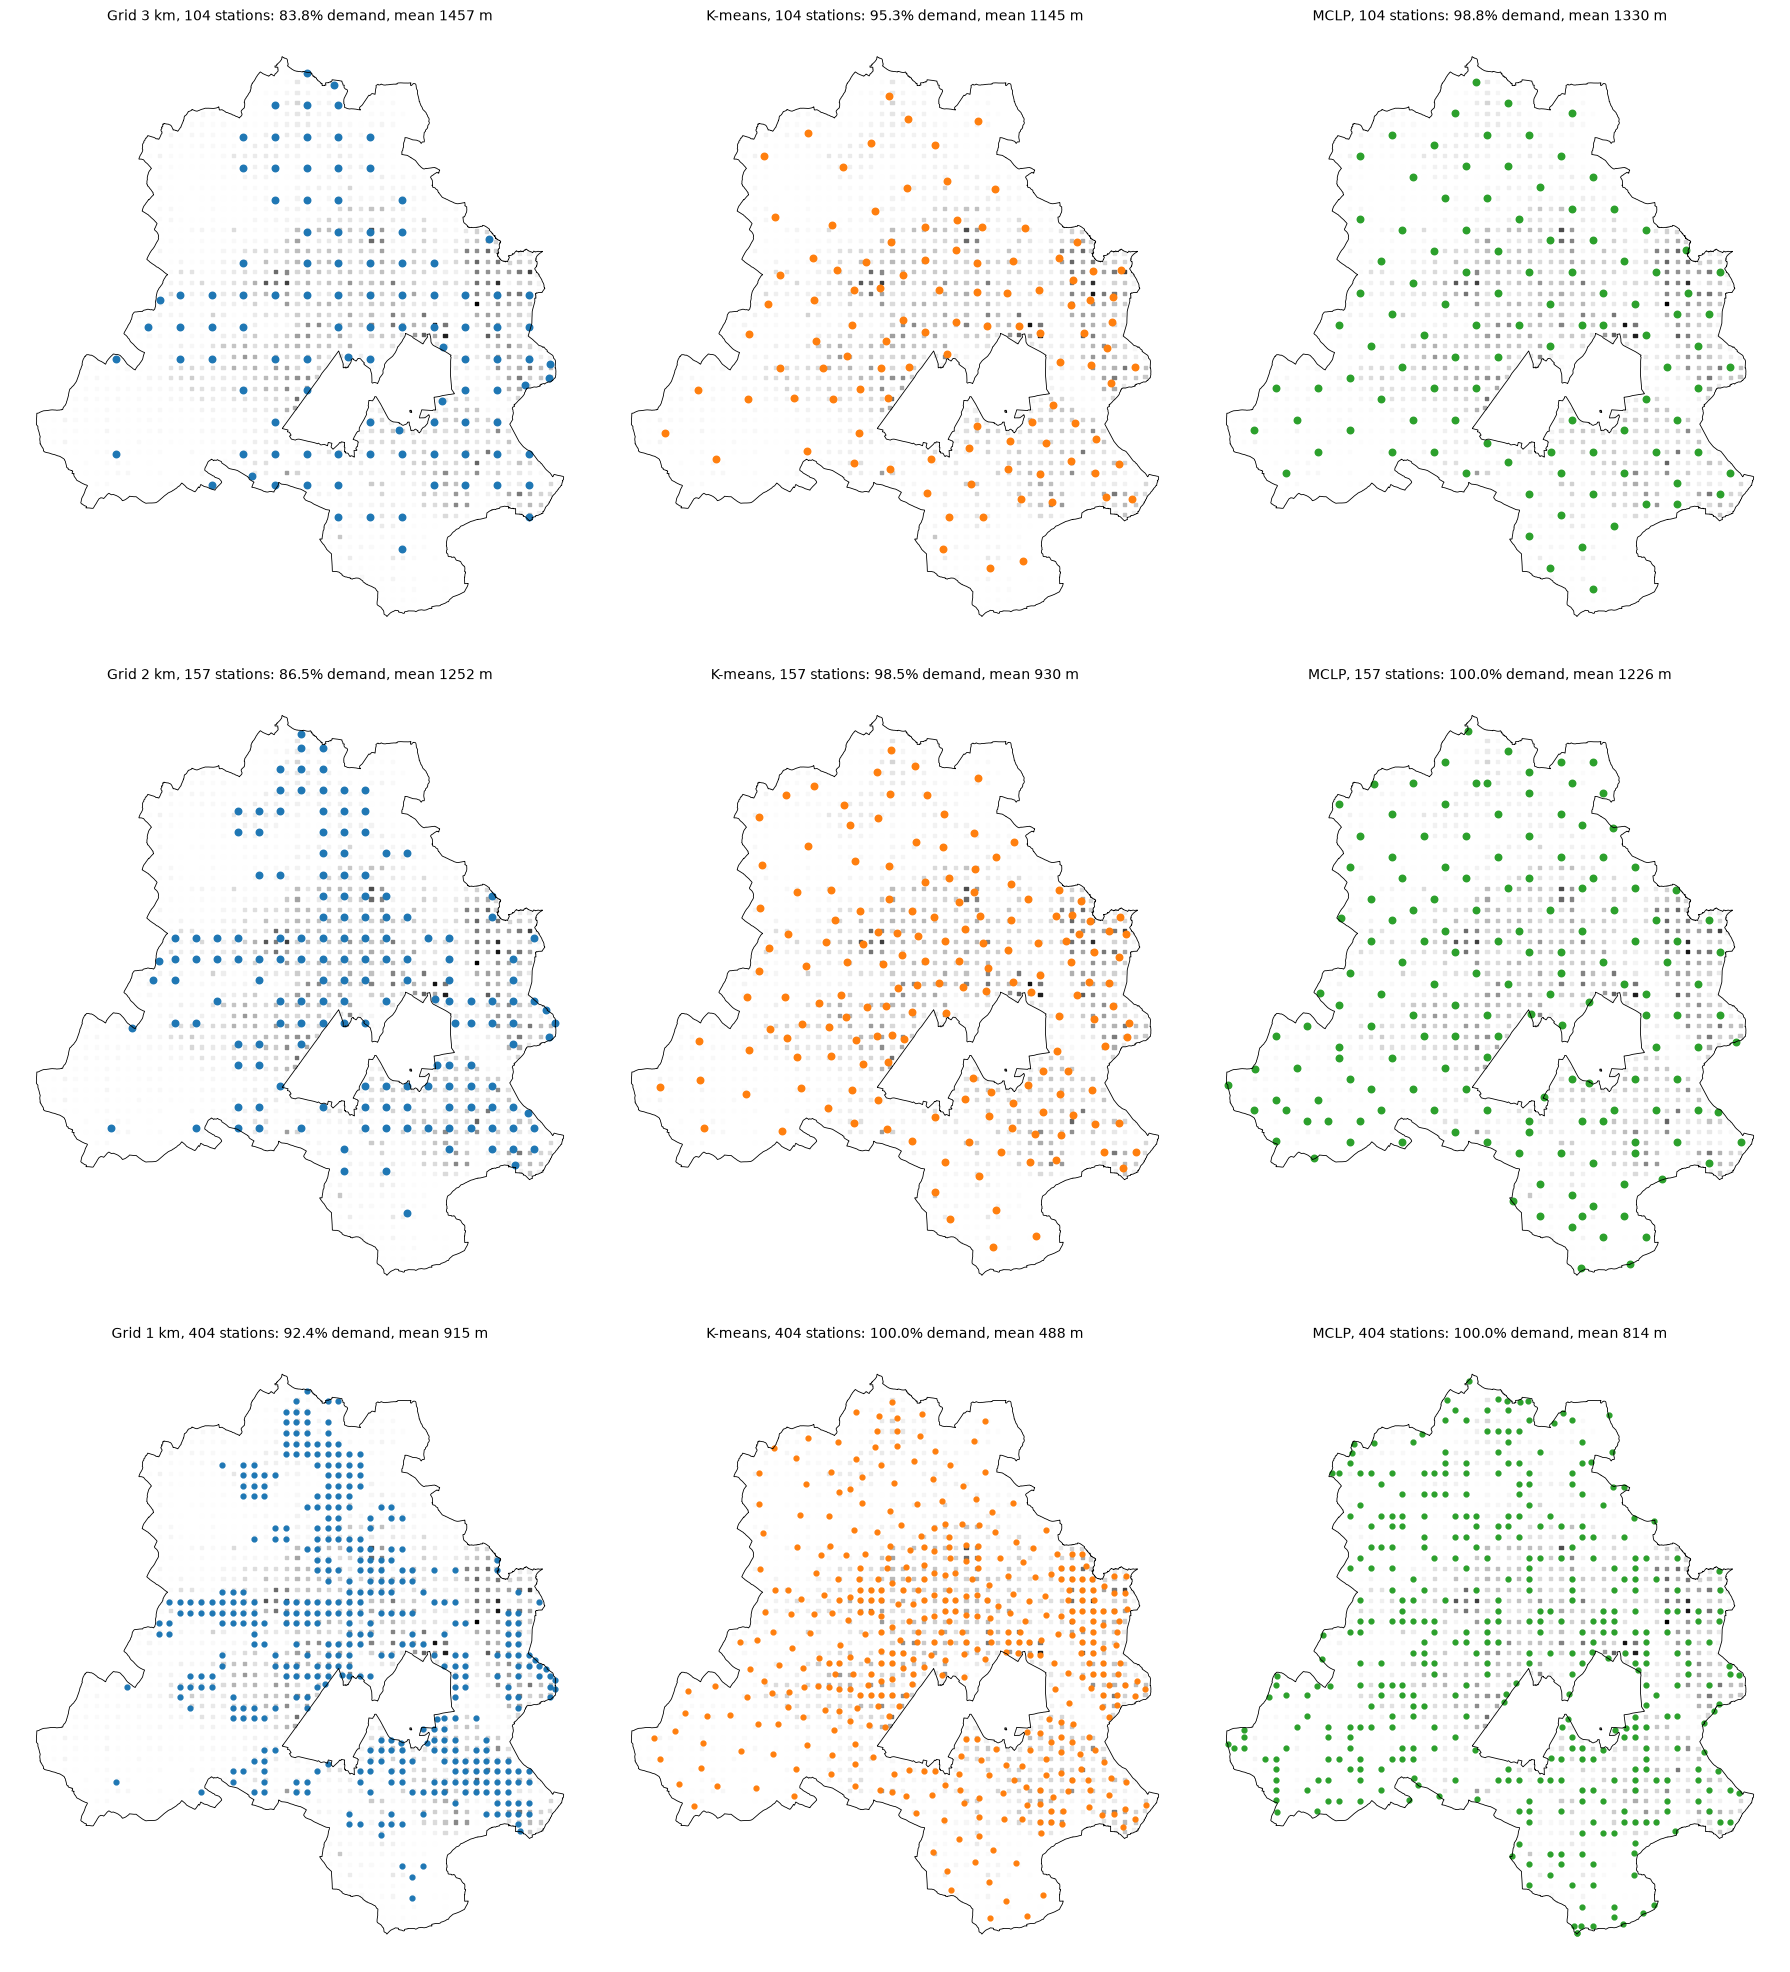

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(18, 20))
for i, (k, gk) in enumerate([(104, 3), (157, 2), (404, 1)]):
    for j, (nm, S) in enumerate([(f"Grid {gk} km", sl.xy(grids[gk])), ("K-means", bud[k]["K-means"]), ("MCLP", bud[k]["MCLP"])]):
        ax = axes[i, j]
        B["study"].boundary.plot(ax=ax, color="k", lw=0.6)
        ax.scatter(X[:, 0], X[:, 1], c=w, s=5, cmap="Greys", marker="s")
        ax.scatter(S[:, 0], S[:, 1], s=12 if k > 200 else 22, c=["tab:blue", "tab:orange", "tab:green"][j])
        dd = cKDTree(S).query(X)[0]
        ax.set_title(f"{nm}, {len(S)} stations: {100 * w[dd <= 2100].sum() / w.sum():.1f}% demand, "
                     f"mean {np.average(dd, weights=w):.0f} m", fontsize=10)
        ax.set_axis_off(); ax.set_aspect("equal")
plt.tight_layout(); plt.savefig(OUT / "budget_maps.png", dpi=110, bbox_inches="tight"); plt.show()

## 7. Exports

In [15]:
card.to_csv(OUT / "scorecard_A.csv"); reg.to_csv(OUT / "regret_A.csv"); reg_summary.to_csv(OUT / "regret_summary_A.csv")
pair.to_csv(OUT / "pairwise_agreement.csv"); cardB.to_csv(OUT / "scorecard_B.csv"); curve.to_csv(OUT / "scenarioB_new_station_curve.csv", index=False)
extA.to_csv(OUT / "extensions.csv"); capdf.to_csv(OUT / "capacity.csv"); gcard.to_csv(OUT / "grid_sizes.csv"); budf.to_csv(OUT / "budgets.csv")
LAYOUTS.update({f"ext_{i}": S for i, S in enumerate(ext_layouts.values())})
gpkg = Path("outputs") / "siting_all_layouts_v1.gpkg"
if gpkg.exists():
    gpkg.unlink()
names = {**{n: n for n in LAYOUTS if not n.startswith("ext_")}, **{f"ext_{i}": n for i, n in enumerate(ext_layouts)}}
index_rows = []
for key, S in LAYOUTS.items():
    lyr = key if not key.startswith("ext_") else "ext_" + "".join(ch if ch.isalnum() else "_" for ch in names[key])[:50]
    gpd.GeoDataFrame({"station_id": np.arange(len(S)), "x": S[:, 0], "y": S[:, 1]},
                     geometry=gpd.points_from_xy(S[:, 0], S[:, 1]), crs=sl.CRS).to_file(gpkg, layer=lyr, driver="GPKG")
    index_rows.append(dict(layer=lyr, description=names[key], stations=len(S)))
cons.to_file(gpkg, layer="consensus_sites", driver="GPKG")
B["existing_4w"][["station_name", "geometry"]].to_file(gpkg, layer="existing_4w", driver="GPKG")
pd.DataFrame(index_rows).to_csv(OUT / "layers_index.csv", index=False)
print("Saved", OUT, "and", gpkg, f"({len(index_rows)} layouts)")

Saved outputs/evaluation_v1 and outputs/siting_all_layouts_v1.gpkg (27 layouts)
